# Stiffened panel bays

This example computes the buckling loads of a laminated panel bay with one blade stiffener. It compares the 1D and 2D models of the stiffener flange, with and without a base, and checks that dividing the skin into panels leaves the unstiffened result unchanged.

A `StiffPanelBay` is a single Ritz domain for the skin, with $m \times n$ terms of the bay. The skin is made of panels, separated along $y$, that may have their own laminates and loads, and the blade stiffeners lie at the edges between the panels, see [Stiffened panels](../stiffened_panels.rst). The stiffener is a `BladeStiff1D`, whose flange has a 1D formulation (a beam along $x$ at the constant coordinate $y_s$), or a `BladeStiff2D`, whose flange is a plate domain, `plate_clpt_donnell`, with its own $m_f \times n_f$ terms. The optional base (pad-up) between the skin and the flange is a `Shell` over $y_s - b_b/2 \le y \le y_s + b_b/2$, with the approximation functions of the skin and an offset. The matrices of the bay are those of the skin plus those of the stiffeners, and are used like those of a `Shell`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import lb
from panels.shell import Shell
from panels.stiffpanelbay import StiffPanelBay


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))

## The bay

The flat bay has the laminate $[0/90/90/0/0]$ of plies of 0.134 mm, $(E_{11}, E_{22}, \nu_{12}, G_{12}, G_{13}, G_{23}) = (105, 10.5, 0.25, 5.25, 5.25, 5.25)$ GPa/-, and density 1600 kg/m³. It has width $b = 100 h$ and length $a = 2b$, with the default simply supported edges. It is made of two panels, each with a constant compression `Nxx` = -1 N/m, so the load multiplier is the critical $N_{xx}$ of the skin in N/m. The stiffener at $y = b/2$ has a flange of height $9h$ with the laminate of the skin and, optionally, a base of width $10h$.

In [2]:
plyt = 0.134e-3
stack = [0, 90, 90, 0, 0]
tskin = len(stack)*plyt
b = 100*tskin
laminaprop = (105.e9, 10.5e9, 0.25, 5.25e9, 5.25e9, 5.25e9)
MF, NF = 6, 5


def bay(stiffener=None, m=8, n=8):
    sb = StiffPanelBay()
    sb.a = 2*b
    sb.b = b
    sb.r = None
    sb.model = 'plate_clpt_donnell'
    sb.stack = stack
    sb.plyt = plyt
    sb.laminaprop = laminaprop
    sb.rho = 1600.
    sb.m = m
    sb.n = n
    sb.add_panel(0, b/2, Nxx=-1.)
    sb.add_panel(b/2, b, Nxx=-1.)
    flange = dict(ys=b/2, bf=9*tskin, fstack=stack, fplyt=plyt,
                  flaminaprop=laminaprop)
    base = dict(bb=10*tskin, bstack=stack, bplyt=plyt, blaminaprop=laminaprop)
    if stiffener == '1D':
        sb.add_bladestiff1d(**flange)
    elif stiffener == '1D with base':
        sb.add_bladestiff1d(**flange, **base)
    elif stiffener == '2D':
        sb.add_bladestiff2d(**flange, mf=MF, nf=NF)
    elif stiffener == '2D with base':
        sb.add_bladestiff2d(**flange, **base, mf=MF, nf=NF)
    return sb

## Linear buckling

The linear buckling problem $(\boldsymbol{K}_C + \lambda \boldsymbol{K}_G)\boldsymbol{c} = \boldsymbol{0}$ is solved with the matrices of the bay, `StiffPanelBay.calc_kC` and `StiffPanelBay.calc_kG`.

In [3]:
critical = {}
modes = {}
for stiffener in (None, '1D', '1D with base', '2D', '2D with base'):
    sb = bay(stiffener)
    eigvals, eigvecs = lb(sb.calc_kC(silent=True), sb.calc_kG(silent=True),
                          silent=True, num_eigvalues=3)
    critical[stiffener] = eigvals[0]
    modes[stiffener] = (sb, eigvecs[:, 0])
    print('%-14s: first load multipliers %s N/m'
          % (stiffener or 'unstiffened', np.round(eigvals, 2)))

unstiffened   : first load multipliers [ 7284.54  7697.68 13773.56] N/m
1D            : first load multipliers [25482.2  27478.31 32315.51] N/m


1D with base  : first load multipliers [33703.41 37244.38 39717.24] N/m
2D            : first load multipliers [27588.35 27699.69 34617.04] N/m


2D with base  : first load multipliers [36670.98 37357.67 42217.05] N/m


The stiffener raises the critical load several times, and the base raises it further. The first modes of the skin:

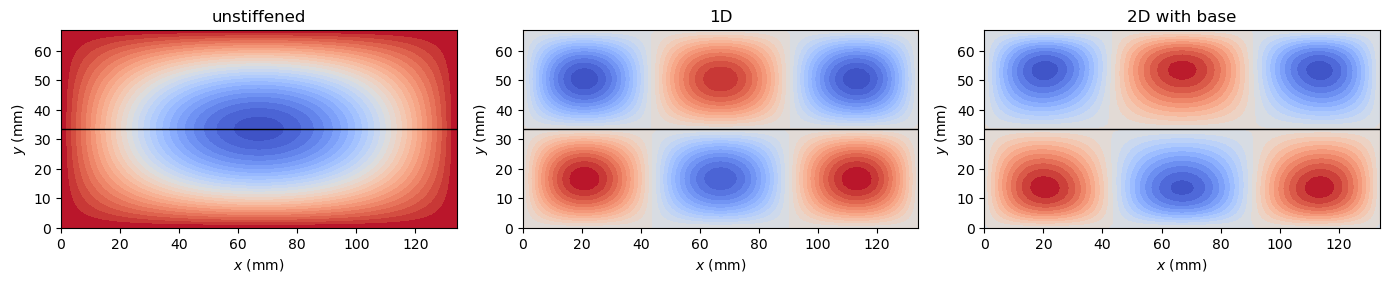

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, key in zip(axes, (None, '1D', '2D with base')):
    sb, c = modes[key]
    u, v, w, phix, phiy = sb.uvw_skin(c, gridx=81, gridy=41)
    cf = ax.contourf(sb.Xs*1e3, sb.Ys*1e3, w, levels=30, cmap='coolwarm')
    ax.axhline(b/2*1e3, color='k', lw=1)
    ax.set_title(key or 'unstiffened')
    ax.set_xlabel('$x$ (mm)')
    ax.set_ylabel('$y$ (mm)')
    ax.set_aspect('equal')
fig.tight_layout()
plt.show()

## Dividing the skin into panels

The panels of a bay share the approximation functions of the bay. Dividing an unstiffened skin into three panels gives nearly the buckling loads of a single `Shell` with the same terms, here $14 \times 14$.

In [5]:
sb = bay(m=14, n=14)
sb.panels = []
for y1, y2 in zip([0, b/3, 2*b/3], [b/3, 2*b/3, b]):
    sb.add_panel(y1=y1, y2=y2, Nxx=-1.)
eig_bay, _ = lb(sb.calc_kC(silent=True), sb.calc_kG(silent=True), silent=True,
                num_eigvalues=4)
s = Shell(a=sb.a, b=sb.b, r=None, stack=stack, plyt=plyt,
          laminaprop=laminaprop, model=sb.model, m=sb.m, n=sb.n)
s.Nxx = -1.
eig_shell, _ = lb(s.calc_kC(silent=True), s.calc_kG(silent=True), silent=True,
                  num_eigvalues=4)
print('bay of three panels: %s N/m' % np.round(eig_bay[:3], 4))
print('single Shell:        %s N/m' % np.round(eig_shell[:3], 4))

bay of three panels: [ 7262.7686  7689.5736 13448.611 ] N/m
single Shell:        [ 7254.0285  7686.5826 13446.5206] N/m


## Results

No literature value is available for this bay. The comparisons below have as reference the single `Shell` for the divided skin and the `BladeStiff1D` for the `BladeStiff2D` flange; the panels unit tests `tests/tests_stiffpanelbay/test_stiffpanelbay_lb.py` and `test_stiffpanelbay_api.py` check them within $3 \times 10^{-3}$ and 20%; here they agree within 0.12% and 9%. The two flange models are different formulations and agree only roughly.

In [6]:
rows = [('unstiffened skin of three panels, mode %d (N/m)' % (i + 1),
         eig_bay[i], eig_shell[i], 'single `Shell`') for i in range(3)]
rows.append(('`BladeStiff2D` flange, critical $N_{xx}$ (N/m)', critical['2D'],
             critical['1D'], '`BladeStiff1D` flange'))
rows.append(('`BladeStiff2D` flange with base, critical $N_{xx}$ (N/m)',
             critical['2D with base'], critical['1D with base'],
             '`BladeStiff1D` flange with base'))
results_table(rows)

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| unstiffened skin of three panels, mode 1 (N/m) | 7262.77 | 7254.03 | +1.20e-03 | single `Shell` |
| unstiffened skin of three panels, mode 2 (N/m) | 7689.57 | 7686.58 | +3.89e-04 | single `Shell` |
| unstiffened skin of three panels, mode 3 (N/m) | 13448.6 | 13446.5 | +1.55e-04 | single `Shell` |
| `BladeStiff2D` flange, critical $N_{xx}$ (N/m) | 27588.4 | 25482.2 | +8.27e-02 | `BladeStiff1D` flange |
| `BladeStiff2D` flange with base, critical $N_{xx}$ (N/m) | 36671 | 33703.4 | +8.80e-02 | `BladeStiff1D` flange with base |